# 1D Dirichlet and parabolic local correctors

We study $a^\varepsilon(x)=1/(2+\cos(2\pi m x))$, where $m=1/\varepsilon\in\mathbb N$, on $I_\delta=(x_0-\delta,x_0+\delta)$.

The elliptic corrector $Y_\delta$ solves $-(a^\varepsilon(1+Y_\delta'))'=0$ with zero Dirichlet data. The parabolic corrector solves
$$w_t-(a^\varepsilon w')'=(a^\varepsilon)',\qquad w(0)=0,\qquad w|_{\partial I_\delta}=0.$$
We solve this local PDE directly with DOLFINx: continuous P1 finite elements in space and backward Euler in time,
$$\int w_h^{n+1}v_h+\Delta t\int a^\varepsilon (w_h^{n+1})'v_h'
=\int w_h^n v_h-\Delta t\int a^\varepsilon v_h'.$$
No one-mode or truncated spectral approximation is used. A time-step refinement table separates the backward-Euler error from the local-corrector error.

In [16]:
import os
os.environ["CC"] = "/usr/bin/clang"
os.environ["CXX"] = "/usr/bin/clang++"
os.environ["PATH"] = (
    "/usr/bin:/bin:/usr/sbin:/sbin:"
    + os.environ["PATH"]
)
import numpy as np
import matplotlib.pyplot as plt
import ufl
from mpi4py import MPI
from dolfinx import default_scalar_type, fem, mesh
from dolfinx.fem.petsc import LinearProblem

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True})

## Parameters

$x_0=0.5$ is a symmetry point because $m$ is an integer. The patch radius $\delta$ is deliberately not aligned with the microscopic period.

In [17]:
m = 40
epsilon = 1.0 / m
x0 = 0.5
delta = 0.173                 # delta / epsilon = 3.46, not aligned
points_per_period = 35
n_elements = int(np.ceil(2 * delta / epsilon * points_per_period))
print(f"epsilon={epsilon:g}, delta/epsilon={delta/epsilon:.3f}, elements={n_elements}")

epsilon=0.025, delta/epsilon=6.920, elements=485


In [18]:
def coefficient(x, m):
    return 1.0 / (2.0 + np.cos(2.0 * np.pi * m * x))

def true_corrector(x, m):
    return np.sin(2.0 * np.pi * m * x) / (4.0 * np.pi * m)

def true_corrector_gradient(x, m):
    return 0.5 * np.cos(2.0 * np.pi * m * x)

def elliptic_corrector_exact(x, m, x0, delta):
    left = x0 - delta
    right = x0 + delta
    integral_total = (
        2.0 * (right - left)
        + (np.sin(2*np.pi*m*right) - np.sin(2*np.pi*m*left)) / (2*np.pi*m)
    )
    a_delta = (2.0 * delta) / integral_total
    integral_x = (
        2.0 * (x - left)
        + (np.sin(2*np.pi*m*x) - np.sin(2*np.pi*m*left)) / (2*np.pi*m)
    )
    value = -(x - left) + a_delta * integral_x
    gradient = -1.0 + a_delta * (2.0 + np.cos(2*np.pi*m*x))
    return value, gradient, a_delta

## Direct DOLFINx parabolic solve

The coefficient is represented directly in UFL. The right-hand side is assembled weakly as $-\int a^\varepsilon v_h'$, so no numerical derivative of the oscillatory coefficient is needed.

In [19]:
def solve_parabolic_dolfinx(m, x0, delta, n_elements, T, Nt):
    domain = mesh.create_interval(
        MPI.COMM_SELF, n_elements, [x0-delta, x0+delta]
    )
    V = fem.functionspace(domain, ("Lagrange", 1))
    boundary_facets = mesh.locate_entities_boundary(
        domain, 0, lambda x: np.full(x.shape[1], True)
    )
    boundary_dofs = fem.locate_dofs_topological(V, 0, boundary_facets)
    bc = fem.dirichletbc(default_scalar_type(0), boundary_dofs, V)

    x_ufl = ufl.SpatialCoordinate(domain)[0]
    a_ufl = 1.0 / (2.0 + ufl.cos(2.0*np.pi*m*x_ufl))
    trial = ufl.TrialFunction(V)
    test = ufl.TestFunction(V)
    previous = fem.Function(V)
    dt = default_scalar_type(T / Nt)

    lhs = (trial*test + dt*a_ufl*trial.dx(0)*test.dx(0))*ufl.dx
    rhs = (previous*test - dt*a_ufl*test.dx(0))*ufl.dx
    problem = LinearProblem(
        lhs, rhs, bcs=[bc], petsc_options_prefix="corrector_1d_",
        petsc_options={"ksp_type": "preonly", "pc_type": "lu"},
    )

    for _ in range(Nt):
        current = problem.solve()
        current.x.scatter_forward()
        previous.x.array[:] = current.x.array

    coordinates = V.tabulate_dof_coordinates()[:, 0]
    order = np.argsort(coordinates)
    return coordinates[order], previous.x.array[order].copy()

T = 0.445 * epsilon**2
Nt_values = [25, 50, 100, 200]
solutions = {}
for Nt in Nt_values:
    x, solutions[Nt] = solve_parabolic_dolfinx(m, x0, delta, n_elements, T, Nt)

w_best = solutions[Nt_values[-1]]
y_exact, y_exact_grad, a_delta = elliptic_corrector_exact(x, m, x0, delta)
print(f"finite-cell coefficient a_delta={a_delta:.12f}; a0=0.5")
print(f"T/epsilon^2={T/epsilon**2:.6g}; finest Nt={Nt_values[-1]}")

finite-cell coefficient a_delta=0.502785426854; a0=0.5
T/epsilon^2=0.445; finest Nt=200


In [20]:
def errors_on_inner(x, u, m, x0, inner_radius):
    mid = 0.5 * (x[:-1] + x[1:])
    h = np.diff(x)
    mask_e = np.abs(mid - x0) <= inner_radius
    grad_u = np.diff(u) / h
    grad_true = true_corrector_gradient(mid, m)
    h1_semi = np.sqrt(np.sum(h[mask_e] * (grad_u[mask_e] - grad_true[mask_e])**2))

    mask_n = np.abs(x - x0) <= inner_radius
    xn = x[mask_n]
    difference = u[mask_n] - true_corrector(xn, m)
    l2_raw = np.sqrt(np.trapezoid(difference**2, xn))
    difference_aligned = difference - np.trapezoid(difference, xn) / (xn[-1] - xn[0])
    l2_aligned = np.sqrt(np.trapezoid(difference_aligned**2, xn))
    return h1_semi, l2_raw, l2_aligned

inner_radius = 0.5 * delta
y_h = y_exact
print(" Nt      dt/epsilon^2       inner H1 error")
for Nt in Nt_values:
    error = errors_on_inner(x, solutions[Nt], m, x0, inner_radius)[0]
    print(f"{Nt:4d}      {T/Nt/epsilon**2:11.4e}      {error:11.4e}")
print(f"elliptic inner H1 error: {errors_on_inner(x,y_h,m,x0,inner_radius)[0]:.4e}")

 Nt      dt/epsilon^2       inner H1 error
  25       1.7800e-02       1.7342e-04
  50       8.9000e-03       1.6177e-04
 100       4.4500e-03       1.5817e-04
 200       2.2250e-03       1.5678e-04
elliptic inner H1 error: 2.4087e-03


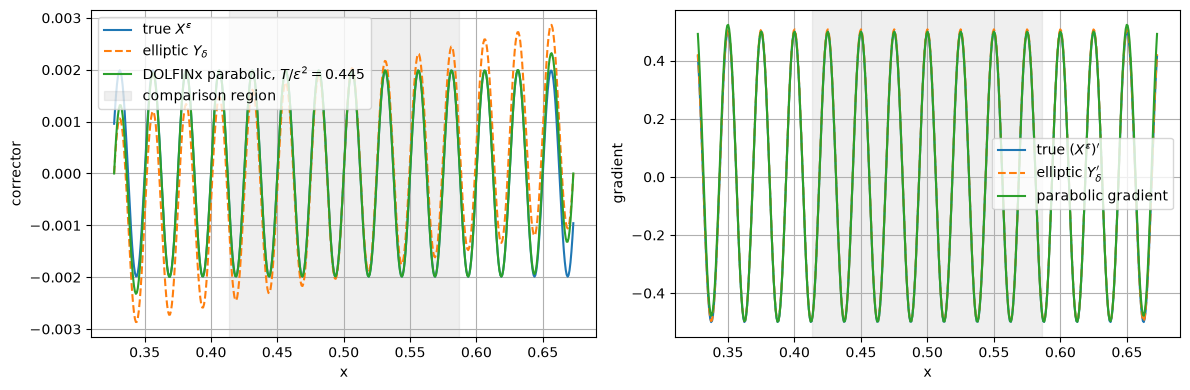

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(x, true_corrector(x, m), label=r"true $X^\varepsilon$")
axes[0].plot(x, y_h, '--', label=r"elliptic $Y_\delta$")
axes[0].plot(x, w_best, label=rf"parabolic, $T/\varepsilon^2={T/epsilon**2:.3g}$")
axes[0].axvspan(x0-inner_radius, x0+inner_radius, color='grey', alpha=.12, label='comparison region')
axes[0].set_xlabel('x'); axes[0].set_ylabel('corrector'); axes[0].legend()

mid = 0.5*(x[:-1]+x[1:])
axes[1].plot(mid, true_corrector_gradient(mid, m), label=r"true $(X^\varepsilon)'$")
axes[1].plot(mid, np.diff(y_h)/np.diff(x), '--', label=r"elliptic $Y_\delta'$")
axes[1].plot(mid, np.diff(w_best)/np.diff(x), label='parabolic gradient')
axes[1].axvspan(x0-inner_radius, x0+inner_radius, color='grey', alpha=.12)
axes[1].set_xlabel('x'); axes[1].set_ylabel('gradient'); axes[1].legend()
plt.tight_layout(); plt.show()

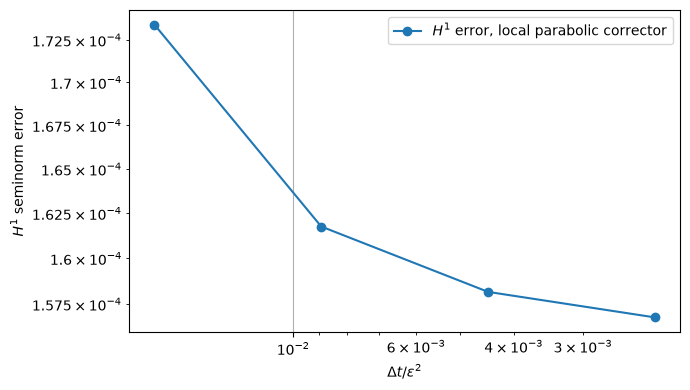

In [25]:
dt_scaled = np.array([T/Nt/epsilon**2 for Nt in Nt_values])
h1_time = np.array([errors_on_inner(x, solutions[Nt], m, x0, inner_radius)[0] for Nt in Nt_values])
plt.loglog(dt_scaled, h1_time, 'o-', label=r"$H^1$ error, local parabolic corrector")
plt.gca().invert_xaxis()
plt.xlabel(r"$\Delta t/\varepsilon^2$")
plt.ylabel(r"$H^1$ seminorm error")
plt.legend(); plt.tight_layout(); plt.show()

## Elliptic versus parabolic error as $\delta/\varepsilon$ grows

Both errors are measured in the $H^1$ seminorm on the inner half-patch $|x-x_0|\leq\delta/2$. For the parabolic problem we use the balanced scaling
$$\frac{T}{\varepsilon^2}=\frac{\sqrt3}{4\pi}\frac{\delta}{\varepsilon},$$
because the distance from the inner region to the artificial boundary is $\delta/2$. During the sweep, $h/\varepsilon$ and $\Delta t/\varepsilon^2$ are held fixed, so the number of elements and time steps both grow with $R$. We show both the absolute seminorm and its RMS normalization by $\sqrt{|I_{\delta/2}|}$. We fit the elliptic data by $CR^{-p}$ and the parabolic data by $Ce^{-\beta R}$, where $R=\delta/\varepsilon$. The fits are empirical slopes over the indicated finite range, not independent proofs.

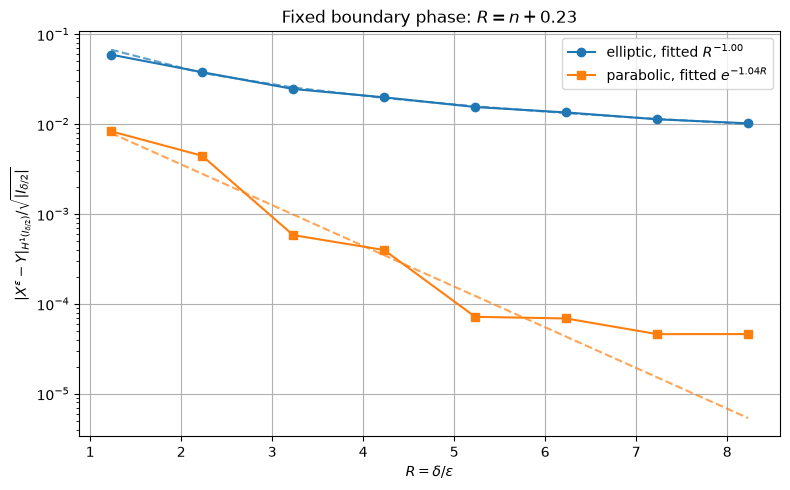

empirical elliptic algebraic order p = 1.001
empirical parabolic exponential rate beta = 1.043
points per period = 100
target Delta t / epsilon^2 = 0.0015
Nt range = 114 ... 757


In [23]:
phase_offset = 0.23
R_values = np.arange(1.0, 9.0) + phase_offset  # fixed boundary phase R mod 1
elliptic_h1 = []
parabolic_h1 = []
sweep_dt_scaled = 1.5e-3          # fixed Delta t / epsilon^2
sweep_points_per_period = 100     # reduce the P1 gradient-error floor
sweep_Nt_values = []

for R in R_values:
    d = R * epsilon
    n_el = int(np.ceil(2 * R * sweep_points_per_period))
    T_R = epsilon**2 * (np.sqrt(3)/(4*np.pi)) * R
    Nt_R = int(np.ceil((T_R/epsilon**2) / sweep_dt_scaled))
    sweep_Nt_values.append(Nt_R)
    xx, w_par = solve_parabolic_dolfinx(m, x0, d, n_el, T_R, Nt_R)
    y_ell, _, _ = elliptic_corrector_exact(xx, m, x0, d)
    elliptic_h1.append(errors_on_inner(xx, y_ell, m, x0, 0.5*d)[0])
    parabolic_h1.append(errors_on_inner(xx, w_par, m, x0, 0.5*d)[0])

elliptic_h1 = np.asarray(elliptic_h1)
parabolic_h1 = np.asarray(parabolic_h1)
inner_lengths = epsilon * R_values
elliptic_rms = elliptic_h1 / np.sqrt(inner_lengths)
parabolic_rms = parabolic_h1 / np.sqrt(inner_lengths)
fit = (R_values >= 2.0) & (R_values <= 7.0)
p_ell = -np.polyfit(np.log(R_values[fit]), np.log(elliptic_rms[fit]), 1)[0]
beta_par = -np.polyfit(R_values[fit], np.log(parabolic_rms[fit]), 1)[0]
C_ell = np.exp(np.mean(np.log(elliptic_rms[fit]) + p_ell*np.log(R_values[fit])))
C_par = np.exp(np.mean(np.log(parabolic_rms[fit]) + beta_par*R_values[fit]))

plt.figure(figsize=(8, 5))
plt.semilogy(R_values, elliptic_rms, 'o-', label=rf"elliptic, fitted $R^{{-{p_ell:.2f}}}$")
plt.semilogy(R_values, parabolic_rms, 's-', label=rf"parabolic, fitted $e^{{-{beta_par:.2f}R}}$")
plt.semilogy(R_values, C_ell*R_values**(-p_ell), '--', color='C0', alpha=.7)
plt.semilogy(R_values, C_par*np.exp(-beta_par*R_values), '--', color='C1', alpha=.7)
plt.xlabel(r"$R=\delta/\varepsilon$")
plt.ylabel(r"$|X^\varepsilon-Y|_{H^1(I_{\delta/2})}/\sqrt{|I_{\delta/2}|}$")
plt.title(rf"Fixed boundary phase: $R=n+{phase_offset}$")
plt.legend()
plt.tight_layout(); plt.show()
print(f"empirical elliptic algebraic order p = {p_ell:.3f}")
print(f"empirical parabolic exponential rate beta = {beta_par:.3f}")
print(f"points per period = {sweep_points_per_period}")
print(f"target Delta t / epsilon^2 = {sweep_dt_scaled:g}")
print(f"Nt range = {min(sweep_Nt_values)} ... {max(sweep_Nt_values)}")

### What this notebook demonstrates

1. The assembled steady finite-element corrector agrees with the available analytic Dirichlet formula.
2. The local forced parabolic equation is solved directly by DOLFINx, not by a selected Fourier/eigenmode.
3. The $N_t$ refinement table checks the backward-Euler time error.
4. The physically relevant quantity is the gradient error. Raw and mean-aligned $L^2$ are both available in `errors_on_inner`; in this symmetric example they may coincide.
5. On an inner region, finite parabolic time can reduce artificial-boundary contamination; taking $T\to\infty$ returns the ordinary Dirichlet corrector.